# Estimating single-index model performance under unknown, high-dimensional covariate shift

In [1]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 1 # num signals. L-1 changepoints

δ_list = [3.0, 4.0]
noise_std = 0.2

def huber_loss(t, epsilon = 1.35):
    residual = t
    condition = jnp.abs(residual) < epsilon
    squared_loss = jnp.square(residual)
    linear_loss = 2 * epsilon * (jnp.abs(residual) - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)
def M(t): return huber_loss(t)

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

ρ̂_list = [[] for _ in (δ_list)]
ρ_list = [[] for _ in (δ_list)]
ρ̂_minus_ρ_list = [[] for _ in (δ_list)]
ρ̂_minus_ρ_test_list = [[] for _ in (δ_list)]
Δρ_trials_list = [[] for _ in δ_list]

# Generate a non-trivial covariance matrix Σ_test
Σ_test = np.zeros((p, p))
for i in range(p):
    for j in range(p):
        Σ_test[i, j] = 0.99 ** np.abs(i - j)
L_chol_test = scipy.linalg.cholesky(Σ_test, lower = True)

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)

    # Gaussian Signal Prior
    γ_squared = 2.3
    B̃_cov = γ_squared * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    ρ̂ = np.eye(L)
    print("True ρ: ", ρ)
    ρ_test = 1/δ * 1/p * B̃.T @ Σ_test @ B̃
    print("True ρ_test: ", ρ_test)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))
    Θ = X @ B̃
    ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
    y = Θ.flatten() + ε.flatten()

    Δρ_arr = [np.linalg.norm(ρ - ρ̂)]
    print("Δρ: ", np.linalg.norm(ρ - ρ̂))
    # Ideas to fix: use the exact same noise vector, 
    for j in tqdm(range(4)): 
        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        Θ̂_erm = np.zeros((n, L))
        Θ_t_erm = np.zeros((n, L))
        ν = np.zeros((L, L))
        κ_mat = np.zeros((L, L))

        # π = ϕ[ℓ_, :]
        π = np.ones(n) # Set to a trivial prior to test
        ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
        fractional_chgpt_locations = np.array([])
        μ̃_arr, σ̃, μ_arr, σ, b = fp_lin_model(π, M, ρ̂, L, fractional_chgpt_locations, δ, n, ε)
        ν = μ̃_arr
        κ_mat = (σ̃)**2 / δ
        # print("σ̃ = ", σ̃)
        β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

        # print("Regressing on signal ", ℓ_)
        sample_weight = π
        sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
        sk_lin_reg.fit(X, y, sample_weight = sample_weight)
        β̂ = sk_lin_reg.coef_

        B̂[:, 0] = β̂
        Θ̂_erm[:, 0] = X @ β̂
        print("### --- Debiasing... --- ###")
        # Run actual AMP
        loss = lambda u, v: M(u - v)
        β̂_amp_algo, θ̂_amp_algo, β_t, θ_t = WERM.amp(X, y, n, p, π, loss, max_iter = 20)
        Θ_t_erm[:, 0] = θ_t
        # Θ_t_erm[:, 0] = debias_M_est(X @ β̂, y, b, π, X @ β̂)

        # Solve for ρ
        # Check whether \nu^T \rho \nu + \kappa is positive definite and whether ν is invertible
        rhs = ν[0]**2 * ρ[0] + κ_mat
        # ρ̂ = np.linalg.inv(ν).T @ ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) @ np.linalg.inv(ν) # Attempt to solve for ρ using a solver instead?
        ρ̂ = ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) * (ν[0])**(-2) # Attempt to solve for ρ using a solver instead?
        # ρ̂ = ρ
        lhs = (1/n * Θ_t_erm.T @ Θ_t_erm)
        print("lhs: ", lhs)
        print("rhs: ", rhs)
        print("lhs - rhs: ", lhs - rhs)
        print("ν: ", ν)
        print("κ_mat: ", κ_mat)

        print("ρ: ", ρ)
        print("ρ̂: ", ρ̂)
        print("Δρ: ", np.linalg.norm(ρ - ρ̂))
        print("ρ - ρ̂: ", ρ - ρ̂)
        Δρ_arr.append(np.linalg.norm(ρ - ρ̂))

    ρ̂_minus_ρ_list[i] = (ρ̂ - ρ)[0][0]
    
    ### --- Estimate ρ_test --- ###
    X_test = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol_test.T
    # Estimate the trace of the covariance of the rows of X_test
    est_trace_X_test = np.trace(X_test.T @ X_test) / n
    # B̃_test = B̃ # or 
    # B̃_test = L_chol_test.T @ B̃
    # ρ_test = 1/δ * 1/p * B̃_test.T @ B̃_test
    ρ_test = 1/δ * 1/p * B̃.T @ Σ_test @ B̃
    
    lhs = (1/n * (X_test @ β̂_amp_algo).T @ (X_test @ β̂_amp_algo))
    rhs = (μ̃_arr[0]**2) * ρ_test + (σ̃**2) * est_trace_X_test

    ρ̂_test = (lhs - (σ̃**2) * est_trace_X_test) * (μ̃_arr[0]**(-2))
    
    ρ̂_minus_ρ_test_list[i] = (ρ̂_test - ρ_test)[0][0]

  0%|          | 0/2 [00:00<?, ?it/s]

δ =  3.0
True ρ:  [[2.30763463]]
True ρ_test:  [[1.24496198]]
Δρ:  1.3076346319639303


  0%|          | 0/4 [00:00<?, ?it/s]

Optimization Results: x =  [0.1419938 0.25     ] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 17, 'njev': 2, 'fjac': array([[-9.99999966e-01, -2.61363038e-04],
       [ 2.61363038e-04, -9.99999966e-01]]), 'r': array([ 0.66932475, -1.04548135,  2.64874223]), 'qtf': array([1.12337996e-09, 3.04933196e-11]), 'fvec': array([-3.20105054e-12, -8.74855743e-14])}
μ̃_arr:  [1.]
### --- Debiasing... --- ###


  0%|          | 0/20 [00:00<?, ?it/s]

c:  -0.9011666666666667
Normalized MSE:  3.397324248752451e+31
c:  -1.1284940292689831
Normalized MSE:  0.001849840949840918
c:  -1.2562146888919454
Normalized MSE:  6.528318334683151e-05
c:  -1.3065961508862878
Normalized MSE:  3.0580667047358e-05
c:  -1.3243001786316526
Normalized MSE:  1.0532939820395601e-05
c:  -1.3303086204162538
Normalized MSE:  3.4278988617578953e-06
c:  -1.3323235685700465
Normalized MSE:  9.939974499982282e-07
c:  -1.3329965750555817
Normalized MSE:  3.135077707382003e-07
c:  -1.3332210616698768
Normalized MSE:  1.069180187754075e-07
c:  -1.3332959073445756
Normalized MSE:  3.725971658958898e-08
c:  -1.3333208577702913
Normalized MSE:  1.2857531340629493e-08
c:  -1.3333291747863782
Normalized MSE:  4.468372510834485e-09
c:  -1.3333319471481317
Normalized MSE:  1.5194881701859128e-09
c:  -1.333332871271279
Normalized MSE:  4.807998906336532e-10
c:  -1.3333331793126126
Normalized MSE:  1.5696430857663021e-10
c:  -1.3333332819930894
Normalized MSE:  5.63425612423

... (31 outputs left out)

c:  -0.9087500000000001
Normalized MSE:  2.501668432655118e+31
c:  -1.2725725377107369
Normalized MSE:  0.0016395933498633928
c:  -1.435668712081972
Normalized MSE:  3.406274738720741e-05
c:  -1.4833826709300815
Normalized MSE:  9.980432469317843e-06
c:  -1.4958108615867545
Normalized MSE:  2.5212271636395963e-06
c:  -1.4989505171822959
Normalized MSE:  6.209584685727344e-07
c:  -1.4997374915465185
Normalized MSE:  1.4475986393806984e-07
c:  -1.4999343642716618
Normalized MSE:  3.634788045458967e-08
c:  -1.499983590529391
Normalized MSE:  9.208569624295698e-09
c:  -1.4999958975986878
Normalized MSE:  2.6057005488691994e-09
c:  -1.49999897439757
Normalized MSE:  6.6651489970545e-10
c:  -1.4999997435992611
Normalized MSE:  1.571906506044507e-10
c:  -1.4999999358998077
Normalized MSE:  3.669494959816092e-11
c:  -1.4999999839749516
Normalized MSE:  8.9116826501956e-12
c:  -1.499999995993738
Normalized MSE:  2.2723680907623875e-12
c:  -1.4999999989984336
Normalized MSE:  5.669495292602815e-

100%|██████████| 4/4 [00:53<00:00, 13.42s/it]

c:  -1.4999999999960871
Normalized MSE:  2.092818705399139e-15
lhs:  [[2.32168477]]
rhs:  [2.30725146]
lhs - rhs:  [[0.01443331]]
ν:  [1.]
κ_mat:  0.013011687858168667
ρ:  [[2.29423977]]
ρ̂:  [[2.30867308]]
Δρ:  0.014433309455878618
ρ - ρ̂:  [[-0.01443331]]



100%|██████████| 2/2 [01:47<00:00, 53.61s/it]


In [3]:
print("ρ̂_minus_ρ_list: ", ρ̂_minus_ρ_list)


print("ρ_test: ", ρ_test)
print("ρ̂_test: ", ρ̂_test)
print("ρ_test - ρ̂_test: ", ρ_test - ρ̂_test)

print("\nu: ", ν)
print("\kappa: ", κ_mat)

print("Δρ_arr: ", Δρ_arr)
print("ρ̂_minus_ρ_list: ", ρ̂_minus_ρ_list)
print("ρ̂_minus_ρ_test_list: ", ρ̂_minus_ρ_test_list)
print("ρ̂_list: ", ρ̂_list)
print("ρ_list: ", ρ_list)

# ### --- Estimate ρ_test --- ###
# X_test = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol_test.T
# # Estimate the trace of the covariance of the rows of X_test
# est_trace_X_test = np.trace(X_test.T @ X_test) / n
# # B̃_test = B̃ # or 
# # B̃_test = L_chol_test.T @ B̃
# # ρ_test = 1/δ * 1/p * B̃_test.T @ B̃_test
# ρ_test = 1/δ * 1/p * B̃.T @ Σ_test @ B̃

# lhs = (1/n * (X_test @ β_t).T @ (X_test @ β_t))
# rhs = ν[0]**2 * ρ_test[0][0] + κ_mat * est_trace_X_test

# ρ̂_test = (lhs - κ_mat * est_trace_X_test) * (ν[0])**(-2)

print("lhs: ", lhs)
print("rhs: ", rhs)
print("lhs - rhs: ", lhs - rhs)
print("ρ_test: ", ρ_test)
print("ρ̂_test: ", ρ̂_test)
print("ρ_test - ρ̂_test: ", ρ_test - ρ̂_test)


ρ̂_minus_ρ_list:  [-0.02179905517050784, 0.027583245931153133]
ρ_test:  [[2.2693748]]
ρ̂_test:  2.2538611299622824
ρ_test - ρ̂_test:  [[0.01551367]]

u:  [1.]
\kappa:  0.013650553289193798
Δρ_arr:  [1.2483076210054511, 0.027786843687200857, 0.027285573577852773, 0.027711154608668576, 0.027583245931153133]
ρ̂_minus_ρ_list:  [-0.02179905517050784, 0.027583245931153133]
ρ̂_minus_ρ_test_list:  [Array(0.01550045, dtype=float64), Array(-0.01551367, dtype=float64)]
ρ̂_list:  [[], []]
ρ_list:  [[], []]
lhs:  2.26749957044608
rhs:  [[2.28301324]]
lhs - rhs:  [[-0.01551367]]
ρ_test:  [[2.2693748]]
ρ̂_test:  2.2538611299622824
ρ_test - ρ̂_test:  [[0.01551367]]


### Works!

In [4]:
print("\rho_test: ", ρ_test)
print("\rho: ", ρ)

ho_test:  [[2.2693748]]
ho:  [[2.24830762]]


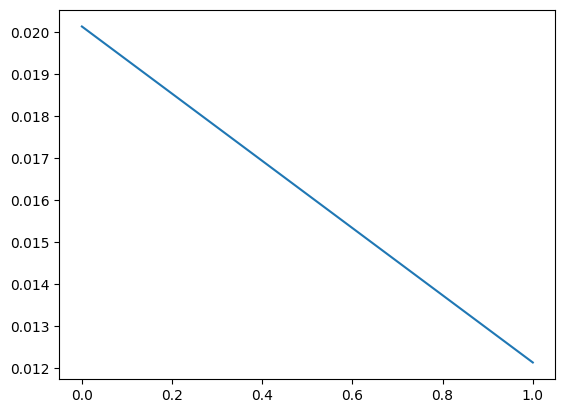

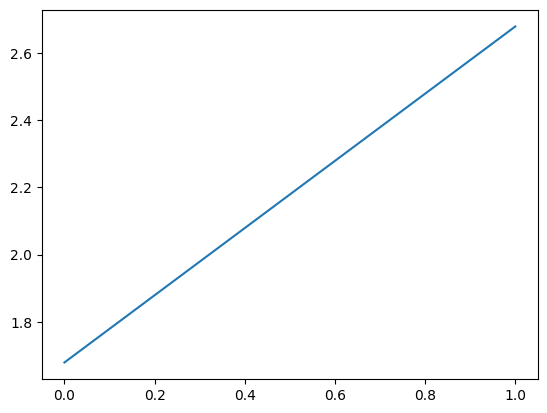

lhs:  4.906762263255971
rhs:  [[2.22842822]]
lhs - rhs:  [[2.67833405]]


In [3]:
plt.plot(ρ̂_minus_ρ_list)
plt.show()

plt.plot(ρ̂_minus_ρ_test_list)
plt.show()

print("lhs: ", lhs)
print("rhs: ", rhs)
print("lhs - rhs: ", lhs - rhs)

In [23]:
i = 0
# Generate a non-trivial covariance matrix Σ_test
Σ_test = np.zeros((p, p))
for i_cov in range(p):
    for j_cov in range(p):
        Σ_test[i_cov, j_cov] = 0.5 ** np.abs(i_cov - j_cov)
L_chol_test = scipy.linalg.cholesky(Σ_test, lower = True)

### --- Estimate ρ_test --- ###
X_test = np.random.normal(0, np.sqrt(1/n), (n, p))
# Estimate the trace of the covariance of the rows of X_test
est_trace_X_test = np.trace(X_test.T @ X_test)
# B̃_test = B̃ # or 
B̃_test = L_chol_test.T @ B̃
ρ_test = 1/δ * 1/p * B̃_test.T @ B̃_test

lhs = (1/n * (X_test @ β_t).T @ (X_test @ β_t))
rhs = ν[0]**2 * ρ_test + κ_mat * (est_trace_X_test / n)

ρ̂_test = (lhs - κ_mat * est_trace_X_test/n) * (ν[0])**(-2)

ρ̂_minus_ρ_test_list[i] = (ρ̂_test - ρ_test)[0][0] 

In [25]:
true_trace_Σ_test = np.trace(Σ_test)
print("true_trace_Σ_test: ", true_trace_Σ_test)
print("est_trace_X_test: ", est_trace_X_test)

print("\nu: ", ν)
print("\kappa: ", κ_mat)

print("ρ̂_test: ", ρ̂_test)
print("ρ_test: ", ρ_test)
print("ρ̂_test - ρ_test: ", ρ̂_minus_ρ_test_list)

print("lhs: ", lhs)
print("rhs: ", rhs)
print("lhs - rhs: ", lhs - rhs)

true_trace_Σ_test:  1000.0
est_trace_X_test:  1000.0095884504528

u:  [1.]
\kappa:  0.02152255042197763
ρ̂_test:  3.9611081990561896
ρ_test:  [[2.2105557]]
ρ̂_test - ρ_test:  [Array(1.7505525, dtype=float64), [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], []]
lhs:  3.9682824513154813
rhs:  [[2.21772995]]
lhs - rhs:  [[1.7505525]]
